# 07. Model Evaluation — Baseline Comparison, Review-Set Labels, Cluster Purity & Error Analysis

**Course:** CSE 276 – CA-1 Academic Project
**Project:** Material Code Harmonisation Across Public Enterprises (IOCL, OIL, NTPC)
**Model under evaluation:** `models/hybrid_er_model.joblib` (trained in Notebook 05)

> **Evaluation integrity.** Three evidence levels are reported separately and never mixed:
> **(1) Held-out synthetic test** — labels known by construction, group-disjoint from training (large *n*, measures the core skill).
> **(2) Review-set labels (AI-assisted, not independent human ground truth)** — the 19 confirmed binary labels from the review app (real data, small *n*; 95 % Wilson intervals reported).
> **(3) Real candidate pairs** — 22,464 unlabelled pairs: descriptive statistics only, no accuracy claims.
> This notebook only reads artefacts written by Notebook 05 / `train_er_model.py`; it re-trains nothing.

In [1]:

import sys, json, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Colab environment setup
if "google.colab" in sys.modules:
    colab_repo = Path("/content/CSE-276-PROJECT")
    if not colab_repo.is_dir():
        subprocess.run(["git", "clone", "https://github.com/SHIVA07605/CSE-276-PROJECT.git", str(colab_repo)], check=True)
    os.chdir(str(colab_repo))
    req_file = colab_repo / "requirements.txt"
    if req_file.exists():
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(req_file)], check=True)
    else:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz", "sentence-transformers"], check=True)

# Locate project root whether the kernel starts in notebooks/ or in the repository root
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG_DIR = PROJECT_ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)

from src.er_pipeline import (METRICS_JSON_PATH, COMPARISON_CSV_PATH, GOLD_COMPARISON_CSV_PATH, GOLD_PREDICTIONS_PATH,
                             REVIEW_PRIORITY_PATH, SCORED_CANDIDATES_PATH, HARMONISED_MASTER_PATH, MUTATION_CSV_PATH)
metrics = json.loads(METRICS_JSON_PATH.read_text(encoding="utf-8"))
test_cmp = pd.read_csv(COMPARISON_CSV_PATH, index_col=0)
gold_cmp = pd.read_csv(GOLD_COMPARISON_CSV_PATH, index_col=0)
gold_pred = pd.read_csv(GOLD_PREDICTIONS_PATH, dtype={"human_label": str})
scored = pd.read_csv(SCORED_CANDIDATES_PATH)
master = pd.read_csv(HARMONISED_MASTER_PATH)
BEST = metrics["selected_model"]
print("Selected model:", BEST, "| thresholds:", {k: round(v, 3) for k, v in metrics["thresholds"].items()})

Project root: C:\project ai


Selected model: hist_gradient_boosting | thresholds: {'binary': 0.805, 'high': 0.85, 'low': 0.25}


---
## 1. Pairwise precision / recall / F1 vs the exact-match baseline (held-out test)

,precision,recall,f1,accuracy,roc_auc,pr_auc
model,,,,,,
logistic_regression,0.9930,0.9852,0.9891,0.9854,0.9979,0.9988
random_forest,0.9960,0.9852,0.9906,0.9874,0.9991,0.9995
hist_gradient_boosting,0.9980,0.9892,0.9936,0.9914,0.9995,0.9998
exact_match_baseline,1.0000,0.0897,0.1646,0.3873,0.5448,0.7024
tfidf_threshold_baseline,0.7777,0.9892,0.8708,0.8024,0.8137,0.8932
minilm_threshold_baseline,0.7657,0.9980,0.8666,0.7931,0.7592,0.8468
rule_engine_baseline,0.9000,0.1064,0.1903,0.3906,0.5410,0.6972


F1 improvement over exact-match baseline: +0.8290  (0.165 -> 0.994)
Recall improvement                      : +0.8995  (0.090 -> 0.989)


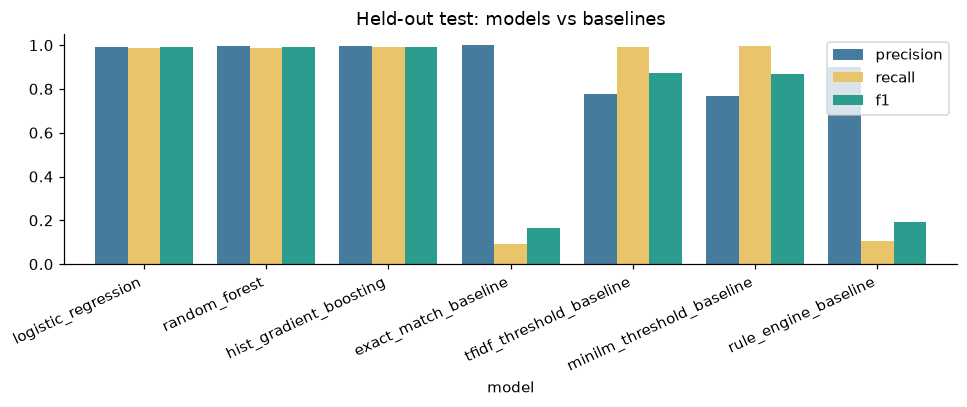

In [2]:
cols = ["precision", "recall", "f1", "accuracy", "roc_auc", "pr_auc"]
display(test_cmp[cols].round(4))
b, m = test_cmp.loc["exact_match_baseline"], test_cmp.loc[BEST]
print(f"F1 improvement over exact-match baseline: {m.f1 - b.f1:+.4f}  ({b.f1:.3f} -> {m.f1:.3f})")
print(f"Recall improvement                      : {m.recall - b.recall:+.4f}  ({b.recall:.3f} -> {m.recall:.3f})")
ax = test_cmp[["precision", "recall", "f1"]].plot.bar(figsize=(9, 3.8), color=["#457b9d", "#e9c46a", "#2a9d8f"], width=0.8)
ax.set_ylim(0, 1.05); ax.set_title("Held-out test: models vs baselines"); ax.set_xticklabels(test_cmp.index, rotation=25, ha="right")
plt.tight_layout(); plt.savefig(FIG_DIR / "07_model_vs_baselines_test.png", bbox_inches="tight"); plt.show()

---
## 2. Review-set labels (AI-assisted, not independent human ground truth) — real-data validation
Only pairs whose `human_label` is `0` or `1` are scored; `UNCERTAIN` and `PENDING` pairs are analysed separately. With *n* = 19 (2 positives) the intervals are wide — this is reported, not hidden. As more pairs are labelled in `review_app.py`, re-running `python train_er_model.py` updates every number automatically.

In [3]:
g = metrics["gold"]
print(f"Review set: {g['n_review_pairs']} pairs | binary review: {g['n_binary']} (+{g['n_positive']} / -{g['n_negative']}) | uncertain: {g['n_uncertain']} | pending: {g['n_pending']}")
display(gold_cmp[["precision", "recall", "f1", "accuracy", "true_positives", "false_positives", "true_negatives", "false_negatives", "precision_95ci", "recall_95ci", "accuracy_95ci"]].round(3))
print("\nDeployed three-way policy on the binary review pairs:")
display(pd.Series(g["deployed_policy_on_binary"]).to_frame("value"))

Review set: 150 pairs | binary review: 19 (+2 / -17) | uncertain: 31 | pending: 100


,precision,recall,f1,accuracy,true_positives,false_positives,true_negatives,false_negatives,precision_95ci,recall_95ci,accuracy_95ci
model,,,,,,,,,,,
logistic_regression,1.000,1.0,1.000,1.000,2,0,17,0,"[0.34, 1.00]","[0.34, 1.00]","[0.83, 1.00]"
random_forest,1.000,1.0,1.000,1.000,2,0,17,0,"[0.34, 1.00]","[0.34, 1.00]","[0.83, 1.00]"
hist_gradient_boosting,1.000,1.0,1.000,1.000,2,0,17,0,"[0.34, 1.00]","[0.34, 1.00]","[0.83, 1.00]"
exact_match_baseline,0.000,0.0,0.000,0.895,0,0,17,2,NaN,"[0.00, 0.66]","[0.69, 0.97]"
tfidf_threshold_baseline,0.200,1.0,0.333,0.579,2,8,9,0,"[0.06, 0.51]","[0.34, 1.00]","[0.36, 0.77]"
minilm_threshold_baseline,0.125,1.0,0.222,0.263,2,14,3,0,"[0.03, 0.36]","[0.34, 1.00]","[0.12, 0.49]"
rule_engine_baseline,1.000,0.5,0.667,0.947,1,0,17,1,"[0.21, 1.00]","[0.09, 0.91]","[0.75, 0.99]"



Deployed three-way policy on the binary review pairs:


,value
n,19.0
auto_merge_count,2.0
auto_reject_count,17.0
review_count,0.0
review_rate,0.0
auto_merge_precision,1.0
auto_reject_npv,1.0
auto_merge_recall,1.0


In [4]:
# Every review decision side by side (binary + uncertain)
show = gold_pred[gold_pred.human_label.isin(["0", "1", "UNCERTAIN"])]
display(pd.crosstab(show.human_label, show.model_decision, margins=True))
print("\nBinary review pairs:")
display(show[show.human_label.isin(["0", "1"])][["pair_id", "human_label", "model_match_probability", "model_decision", "description_1", "description_2"]])

model_decision,EQUIVALENT,NEEDS_REVIEW,NOT_EQUIVALENT,All
human_label,,,,
0,0,0,17,17
1,2,0,0,2
UNCERTAIN,1,28,2,31
All,3,28,19,50



Binary review pairs:


,pair_id,human_label,model_match_probability,model_decision,description_1,description_2
19,PAIR_TFIDF_HIGH_020,1,1.0000,EQUIVALENT,API 6D BALL VALVES (NUMBERS),API 6D BALL VALVES
20,PAIR_TFIDF_HIGH_021,1,1.0000,EQUIVALENT,API 6D VALVES (NUMBERS),API 6D VALVES
30,PAIR_CONFLICT_031,0,0.0000,NOT_EQUIVALENT,"'CONVEYOR BELT (NN / EP) ABOVE 1400MM WIDTH AND UPTO 1600MM WIDTH""...",2.0 MEG DESCRIPTION CONVEYOR BELT (NN/ EP) ABOVE 1600MM WIDTH
31,PAIR_CONFLICT_032,0,0.0000,NOT_EQUIVALENT,"'CONVEYOR BELT (NN / EP) ABOVE 1400MM WIDTH AND UPTO 1600MM WIDTH""...",CONVEYOR BELT (NN/ EP) ABOVE 2000MM WITDH AND UPTO 2200MM WITDH
32,PAIR_CONFLICT_033,0,0.0000,NOT_EQUIVALENT,"'CONVEYOR BELT (NN / EP) ABOVE 1400MM WIDTH AND UPTO 1600MM WIDTH""...",CONVEYOR BELT (NN/ EP) ABOVE 1800MM WIDTH AND UPTO 2000MM WIDTH
33,PAIR_CONFLICT_034,0,0.0000,NOT_EQUIVALENT,"'CONVEYOR BELT (NN / EP) ABOVE 1400MM WIDTH AND UPTO 1600MM WIDTH""...",CONVEYOR BELT (NN/ EP) ABOVE 1600MM WIDTH AND UPTO 1800MM WIDTH
34,PAIR_CONFLICT_035,0,0.0000,NOT_EQUIVALENT,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...
35,PAIR_CONFLICT_036,0,0.0000,NOT_EQUIVALENT,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...
36,PAIR_CONFLICT_037,0,0.0000,NOT_EQUIVALENT,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...
37,PAIR_CONFLICT_038,0,0.0000,NOT_EQUIVALENT,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...,1. THE APPLICANT SHOULD BE MANUFACTURER OF NN/EP CONVEYOR BELT OF ...


In [5]:
# How the model treats the 31 pairs marked UNCERTAIN (generic titles without specifications)
unc = gold_pred[gold_pred.human_label == "UNCERTAIN"]
print("Decisions on UNCERTAIN pairs:", unc.model_decision.value_counts().to_dict())
print("UNCERTAIN pairs auto-merged (the dangerous error):", (unc.model_decision == "EQUIVALENT").sum())
display(unc[unc.model_decision != "NEEDS_REVIEW"][["pair_id", "model_match_probability", "model_decision", "model_reason", "description_1", "description_2"]])

Decisions on UNCERTAIN pairs: {'NEEDS_REVIEW': 28, 'NOT_EQUIVALENT': 2, 'EQUIVALENT': 1}
UNCERTAIN pairs auto-merged (the dangerous error): 1


,pair_id,model_match_probability,model_decision,model_reason,description_1,description_2
14,PAIR_EXACT_015,1.0000,EQUIVALENT,"High match probability (1.000) with shared, non-conflicting specif...",XLPE CABLE FOR WORKING VOLTAGES UP TO AND INCLUDING 1.1 KV,XLPE CABLE FOR WORKING VOLTAGES UP TO AND INCLUDING 1.1 KV
40,PAIR_BOUNDARY_041,0.0120,NOT_EQUIVALENT,Low match probability (0.012 <= 0.250),608 TEST BEARINGS,BEARINGS (QUANTITY- 101 NUMBERS)
49,PAIR_BOUNDARY_050,0.0001,NOT_EQUIVALENT,Low match probability (0.000 <= 0.250),API 610 CENTRIFUGAL PUMP,CENTRIFUGAL PUMP OF DISCHARGE FLOW 60 KL/HR


---
## 2b. AI-assisted Batch-2 evaluation tier (100 pairs blind to model output)
> **Academic Note:** This tier measures agreement with an AI annotator (Claude Opus, applying `docs/annotation_guidelines.md` blind to model output). It is **not independent human ground truth**. The annotator shares the model designer's rules, so routing agreement on UNCERTAIN pairs is expected by design.

Out of 100 candidate pairs:
- **25 binary pairs** (8 positive, 17 negative)
- **75 UNCERTAIN pairs** (generic descriptors, asymmetric specs, lots of mixed items)

In [6]:
b2 = metrics.get("ai_assisted_batch2")
if b2:
    print(f"Batch-2 tier: {b2['n_pairs']} pairs | binary: {b2['n_binary']} (+{b2['n_positive']} / -{b2['n_negative']}) | uncertain: {b2['n_uncertain']}")
    b2_cmp_path = METRICS_JSON_PATH.parent / "model_comparison_ai_assisted_batch2.csv"
    if b2_cmp_path.exists():
        b2_cmp = pd.read_csv(b2_cmp_path, index_col=0)
        display(b2_cmp[["precision", "recall", "f1", "accuracy", "true_positives", "false_positives", "true_negatives", "false_negatives", "precision_95ci", "recall_95ci", "accuracy_95ci"]].round(3))
    print("\nDeployed three-way policy on the Batch-2 binary pairs:")
    display(pd.Series(b2["deployed_policy_on_binary"]).to_frame("value"))
    print("\nDecisions on the 75 UNCERTAIN pairs:", b2["uncertain_pairs_decisions"])
    print("UNCERTAIN pairs auto-merged (safety check):", b2["uncertain_pairs_auto_merged"])
else:
    print("AI-assisted Batch 2 tier not present in metrics.")

Batch-2 tier: 100 pairs | binary: 25 (+8 / -17) | uncertain: 75


,precision,recall,f1,accuracy,true_positives,false_positives,true_negatives,false_negatives,precision_95ci,recall_95ci,accuracy_95ci
model,,,,,,,,,,,
logistic_regression,0.727,1.000,0.842,0.88,8,3,14,0,"[0.43, 0.90]","[0.68, 1.00]","[0.70, 0.96]"
random_forest,0.727,1.000,0.842,0.88,8,3,14,0,"[0.43, 0.90]","[0.68, 1.00]","[0.70, 0.96]"
hist_gradient_boosting,0.727,1.000,0.842,0.88,8,3,14,0,"[0.43, 0.90]","[0.68, 1.00]","[0.70, 0.96]"
exact_match_baseline,0.000,0.000,0.000,0.68,0,0,17,8,NaN,"[0.00, 0.32]","[0.48, 0.83]"
tfidf_threshold_baseline,1.000,0.875,0.933,0.96,7,0,17,1,"[0.65, 1.00]","[0.53, 0.98]","[0.80, 0.99]"
minilm_threshold_baseline,0.320,1.000,0.485,0.32,8,17,0,0,"[0.17, 0.52]","[0.68, 1.00]","[0.17, 0.52]"
rule_engine_baseline,0.600,0.375,0.462,0.72,3,2,15,5,"[0.23, 0.88]","[0.14, 0.69]","[0.52, 0.86]"



Deployed three-way policy on the Batch-2 binary pairs:


,value
n,25.00
auto_merge_count,8.00
auto_reject_count,13.00
review_count,4.00
review_rate,0.16
auto_merge_precision,1.00
auto_reject_npv,1.00
auto_merge_recall,1.00



Decisions on the 75 UNCERTAIN pairs: {'NEEDS_REVIEW': 50, 'NOT_EQUIVALENT': 24, 'EQUIVALENT': 1}
UNCERTAIN pairs auto-merged (safety check): 1


---
## 3. Cluster purity (entities known by construction)
Purity alone rewards putting every record in its own cluster, so **inverse purity** (completeness) and their harmonic mean (F-measure) are reported too. Clusters are formed with the project's `conflict_aware_clustering()`.

,purity,inverse_purity,f_measure,n_records,n_true_entities,n_predicted_clusters
exact_match_baseline,1.0000,0.5448,0.7054,2030.0,1015.0,1939.0
minilm_threshold_0.90,0.9005,0.9025,0.9015,2030.0,1015.0,1011.0
hybrid_model,0.9990,0.9946,0.9968,2030.0,1015.0,1024.0


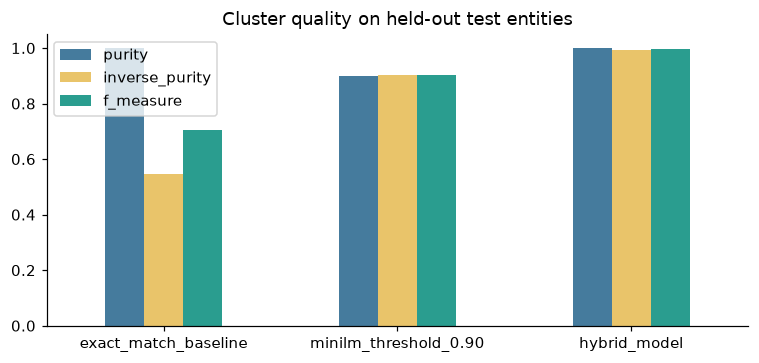

In [7]:
pur = pd.DataFrame(metrics["synthetic_test_cluster_purity"]).T
display(pur)
ax = pur[["purity", "inverse_purity", "f_measure"]].plot.bar(figsize=(7, 3.4), color=["#457b9d", "#e9c46a", "#2a9d8f"])
ax.set_ylim(0, 1.05); ax.set_title("Cluster quality on held-out test entities"); ax.set_xticklabels(pur.index, rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "07_cluster_purity.png", bbox_inches="tight"); plt.show()

---
## 4. All 22,464 real candidate pairs (unlabelled — descriptive only)

Decisions (all pairs)      : {'NOT_EQUIVALENT': 16911, 'NEEDS_REVIEW': 4640, 'EQUIVALENT': 913}
Decisions (cross-enterprise): {'NOT_EQUIVALENT': 696, 'NEEDS_REVIEW': 222, 'EQUIVALENT': 12}
Harmonised clusters: 374 multi-record groups covering 913 records | blocked merges: 50 | transitive conflicts caught: 50


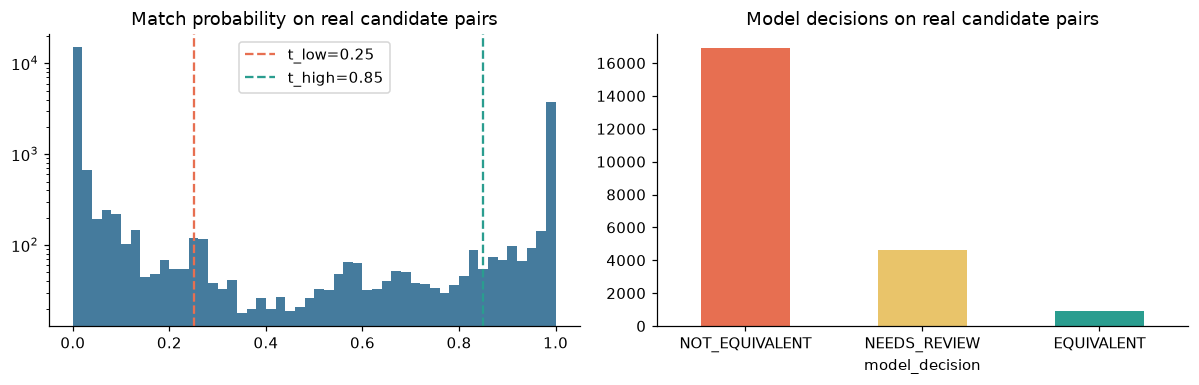

In [8]:
rc = metrics["real_candidates"]
print("Decisions (all pairs)      :", rc["decisions"])
print("Decisions (cross-enterprise):", rc["cross_enterprise_decisions"])
print(f"Harmonised clusters: {rc['multi_record_clusters']} multi-record groups covering {rc['records_in_clusters']} records | blocked merges: {rc['blocked_merges']} | transitive conflicts caught: {rc['transitive_conflicts']}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(scored.model_match_probability, bins=50, color="#457b9d")
for k, c in [("low", "#e76f51"), ("high", "#2a9d8f")]:
    ax[0].axvline(metrics["thresholds"][k], color=c, ls="--", label=f"t_{k}={metrics['thresholds'][k]:.2f}")
ax[0].set_yscale("log"); ax[0].set_title("Match probability on real candidate pairs"); ax[0].legend()
scored.model_decision.value_counts().plot.bar(ax=ax[1], color=["#e76f51", "#e9c46a", "#2a9d8f"])
ax[1].set_title("Model decisions on real candidate pairs"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "07_real_candidate_decisions.png", bbox_inches="tight"); plt.show()

In [9]:
print("Cross-enterprise pairs proposed as EQUIVALENT:")
x = scored[(scored.model_decision == "EQUIVALENT") & scored.is_cross_enterprise.astype(bool)]
display(x[["model_match_probability", "organization_1", "cleaned_description_1", "organization_2", "cleaned_description_2"]].sort_values("model_match_probability", ascending=False).head(15))
print("\nHarmonised master (top proposed groups):")
display(master.head(12)[["harmonised_code", "member_count", "enterprises", "representative_description", "mean_match_probability"]])

Cross-enterprise pairs proposed as EQUIVALENT:


,model_match_probability,organization_1,cleaned_description_1,organization_2,cleaned_description_2
81,1.0000,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVE
82,1.0000,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVE
83,1.0000,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVES
86,1.0000,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVE
87,1.0000,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVE
88,1.0000,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVE
2057,1.0000,NTPC Limited,XLPE CABLE FOR WORKING VOLTAGE UP TO AND INCLUDING 1.1 KV,Oil India Limited,XLPE CABLE FOR WORKING VOLTAGES UP TO AND INCLUDING 1.1 KV
99,1.0000,Indian Oil Corporation Limited,API 6D VALVES (NUMBERS),Oil India Limited,API 6D VALVES
2060,1.0000,NTPC Limited,XLPE CABLE FOR WORKING VOLTAGES UP TO AND INCLUDING 1.1 KV,Oil India Limited,XLPE CABLE FOR WORKING VOLTAGES UP TO AND INCLUDING 1.1 KV
90,0.9982,Indian Oil Corporation Limited,API 6D BALL VALVES (NUMBERS),Oil India Limited,API 6D BALL VALVES QUANTITY 76 NUMBERS



Harmonised master (top proposed groups):


,harmonised_code,member_count,enterprises,representative_description,mean_match_probability
0,HMC-MAT-AD06BD,10,Indian Oil Corporation Limited; Oil India Limited,BALL VALVES API 6D QUANTITY. 36 NUMBERS,0.9990
1,HMC-MAT-9294B7,3,NTPC Limited; Oil India Limited,XLPE CABLE FOR WORKING VOLTAGES UP TO AND INCLUDING 1.1 KV,1.0000
2,HMC-MAT-C3EE15,2,Indian Oil Corporation Limited; Oil India Limited,API 6D VALVES (NUMBERS),1.0000
3,HMC-MAT-C79046,11,Oil India Limited,GATE VALVES API 600. QUANTITY 415 NUMBERS,0.9991
4,HMC-MAT-3CA0F2,10,Oil India Limited,API-6A GATE VALVES .QUANTITY. 300 NUMBERS,0.9895
5,HMC-MAT-932E6E,9,Oil India Limited,5 HP SUBMERSIBLE PUMP SETS - QUANTITY = 60 NUMBER,0.9941
6,HMC-MAT-41484B,8,Oil India Limited,"""API 6D PLUG VALVES"" TOTAL QUANTITY 81 NUMBERS",0.9960
7,HMC-MAT-214557,6,Oil India Limited,LINE PIPE 1INCH BLACK STEEL ERW SCREWED (Q3),1.0000
8,HMC-MAT-B2F91D,6,Oil India Limited,LINE PIPE 2INCH ERW GALVANISED SCREWED (Q3),1.0000
9,HMC-MAT-7DA935,6,Oil India Limited,API 6D GATE VALVE. (QUANTITY. 24 NUMBERS.),0.9965


---
## 5. Active learning — which pending pairs should humans label next?
The 100 `PENDING` Batch-2 pairs are ranked by model uncertainty (probability closest to 0.5 first). Labelling these first gives the most information per reviewer minute (uncertainty sampling).

In [10]:
prio = pd.read_csv(REVIEW_PRIORITY_PATH)
print("Pending-pair decisions:", metrics["gold"]["pending_pairs_decisions"])
display(prio.head(12)[["review_rank", "pair_id", "model_match_probability", "model_decision", "description_1", "description_2"]])

Pending-pair decisions: {'NEEDS_REVIEW': 54, 'NOT_EQUIVALENT': 37, 'EQUIVALENT': 9}


,review_rank,pair_id,model_match_probability,model_decision,description_1,description_2
0,1,PAIR_EXP_043,0.5371,NEEDS_REVIEW,SWING CHECK VALVE (NUMBERS),API 6D SWING CHECK VALVE. (QUANTITY. 92 NUMBERS.)
1,2,PAIR_EXP_084,0.6796,NEEDS_REVIEW,MAGNETIC STIRRER,HOT PLATE MAGNETIC STIRRER
2,3,PAIR_EXP_085,0.6796,NEEDS_REVIEW,MAGNETIC STIRRER,HOT PLATE MAGNETIC STIRRER
3,4,PAIR_EXP_003,0.6880,NEEDS_REVIEW,STEAM TURBINE,OF STEAM TURBINE (ANY CYLINDER) OF 60 MW OR ABOVE CAPACITY POWER P...
4,5,PAIR_EXP_001,0.6996,NEEDS_REVIEW,BALL VALVE (NUMBERS),5. 1/2INCH BALL VALVE-02 NUMBERS
5,6,PAIR_EXP_011,0.7089,NEEDS_REVIEW,STEAM TURBINE,EOI DOCUMENT FOR STUDY FOR STEAM TURBINE DESIGN AT 55% LOAD
6,7,PAIR_EXP_002,0.2869,NEEDS_REVIEW,STEAM TURBINE,3A.24 FACTORY /WORKS WHERE THE STEAM TURBINE EQUAL TO 150 MW
7,8,PAIR_EXP_044,0.2750,NEEDS_REVIEW,API 6D BALL VALVES (NUMBERS),API 6D VALVES
8,9,PAIR_EXP_093,0.8233,NEEDS_REVIEW,GEAR BOX SPARES,SPARES FOR ZF GEAR BOX
9,10,PAIR_EXP_074,0.8353,NEEDS_REVIEW,PIPE & PIPE FITTINGS,PIPE FITTINGS & DELIVERY LINE PIPES


---
## 6. Conclusions & limitations
* **Objective 2 (ER model with pairwise P/R):** delivered — a trained, serialised hybrid classifier with precision, recall, F1, ROC-AUC and PR-AUC on held-out pairs, plus confusion matrices on review-set labels.
* **Objective 3 (metrics vs exact-match baseline, cluster purity):** delivered — the model is compared with exact match and three further baselines on identical pairs; purity / inverse purity are reported.
* **Safety:** explicit specification conflicts are never merged, generic titles and asymmetric specifications are routed to review, and conflict-aware clustering blocks transitive merges.

**Limitations (stated honestly):**
1. Held-out test pairs are *constructed* from real records; real cross-enterprise variation can be messier, so test scores are an upper bound on real-world accuracy.
2. Review-set binary labels are few (19 binary, 2 positive): the review-set confusion matrix is evidence, not a precise estimate — see the Wilson intervals.
3. The genuine annotation for `PAIR_BOUNDARY_041` (UNCERTAIN / MEDIUM) has been restored and the test suite isolated to protect worksheet integrity.
4. Specification parsing is regex-based; unusual units or codes outside the parser are only caught through lexical evidence (see the unseen-mutation detection rate in Notebook 05).